In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Load cleaned dataset
df = pd.read_csv("dataset/cleaned_ecommerce_sales_150k.csv")
df['order_date'] = pd.to_datetime(df['order_date'])

print("Cleaned Dataset Loaded Successfully!")
print("Shape:", df.shape)

Cleaned Dataset Loaded Successfully!
Shape: (138116, 46)


=== DESCRIPTIVE STATISTICS ===


,count,mean,std,min,25%,50%,75%,max
gross_sales,138116.0,1375.384176,1291.009554,6.31,458.9200,995.730,1871.200,16051.19
net_sales,138116.0,1137.762562,1048.447932,4.86,388.9900,838.760,1552.315,15114.85
profit,138116.0,428.859114,409.477691,-1655.64,145.7275,319.665,590.650,5151.44
quantity,138116.0,5.615244,3.371289,1.00,3.0000,5.000,8.000,24.00
discount_amount,138116.0,237.621614,378.779459,0.00,26.3275,103.285,277.125,6759.02


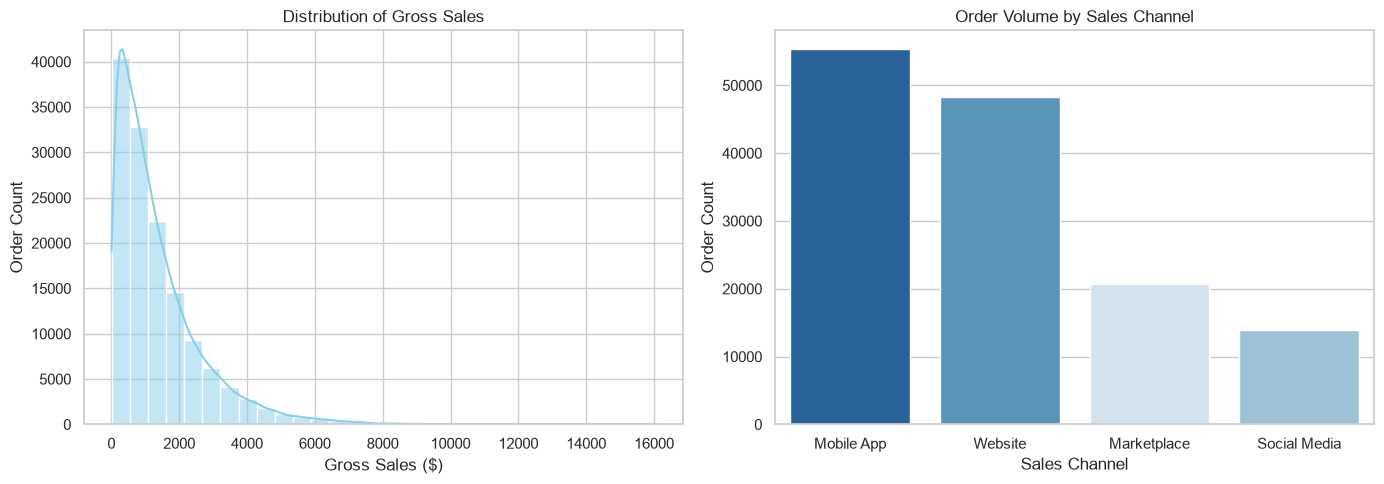

In [4]:
# 1. Summary Statistics for numerical metrics
print("=== DESCRIPTIVE STATISTICS ===")
display(df[['gross_sales', 'net_sales', 'profit', 'quantity', 'discount_amount']].describe().T)

# 2. Visualizing Single Variables
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Gross Sales Distribution
sns.histplot(df['gross_sales'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Gross Sales')
axes[0].set_xlabel('Gross Sales ($)')
axes[0].set_ylabel('Order Count')

# Plot 2: Orders by Sales Channel
sns.countplot(data=df, x='sales_channel', hue='sales_channel', order=df['sales_channel'].value_counts().index, ax=axes[1], palette='Blues_r', legend=False)
axes[1].set_title('Order Volume by Sales Channel')
axes[1].set_xlabel('Sales Channel')
axes[1].set_ylabel('Order Count')

plt.tight_layout()
plt.show()

### Key Insights: Distribution & Sales Channels
* **Gross Sales Distribution:** Right-skewed distribution where most orders cluster under $2,000, with a few high-value purchase outliers stretching past $10,000[cite: 7].
* **Sales Channel Lead:** Mobile App drives the highest order volume across the platform, followed closely by Website sales[cite: 7].

,region,net_sales,profit
3,South,50108520.98,18866524.88
0,Central,33629005.10,12702417.76
4,West,29864717.11,11304365.72
1,East,24595103.68,9232362.22
2,North,18945867.19,7126634.77


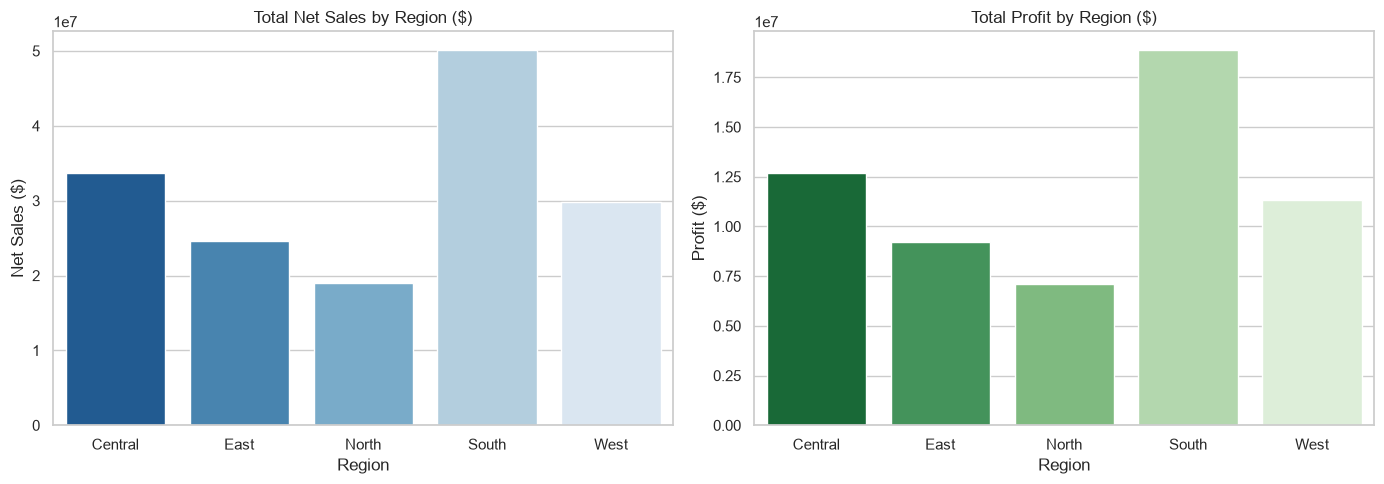

In [5]:
# 1. Group-by aggregation: Total Sales and Profit by Region
region_summary = df.groupby('region')[['net_sales', 'profit']].sum().reset_index()
display(region_summary.sort_values(by='net_sales', ascending=False))

# 2. Visualizing Regional Performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Total Net Sales by Region
sns.barplot(data=region_summary, x='region', y='net_sales', hue='region', ax=axes[0], palette='Blues_r', legend=False)
axes[0].set_title('Total Net Sales by Region ($)')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Net Sales ($)')

# Plot 2: Total Profit by Region
sns.barplot(data=region_summary, x='region', y='profit', hue='region', ax=axes[1], palette='Greens_r', legend=False)
axes[1].set_title('Total Profit by Region ($)')
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Profit ($)')

plt.tight_layout()
plt.show()

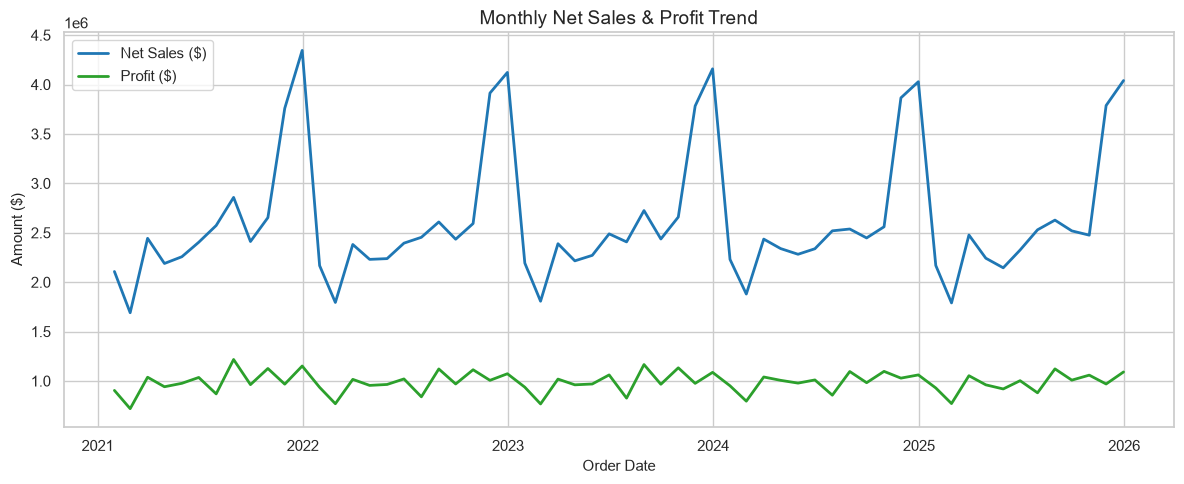

In [6]:
# 1. Group-by aggregation: Monthly Net Sales and Profit trends
df_monthly = df.set_index('order_date').resample('ME')[['net_sales', 'profit']].sum().reset_index()

# 2. Visualizing Monthly Trends
plt.figure(figsize=(12, 5))
plt.plot(df_monthly['order_date'], df_monthly['net_sales'], label='Net Sales ($)', color='#1f77b4', linewidth=2)
plt.plot(df_monthly['order_date'], df_monthly['profit'], label='Profit ($)', color='#2ca02c', linewidth=2)

plt.title('Monthly Net Sales & Profit Trend', fontsize=14)
plt.xlabel('Order Date', fontsize=11)
plt.ylabel('Amount ($)', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

### Key Insights: Monthly Sales & Profit Trends
* **Steady Growth & Seasonality:** Net sales and profit follow a consistent monthly trend across the multi-year timeline, showing predictable seasonal demand surges during late-year periods.
* **Consistent Margins:** Profit tracks net sales smoothly over time, indicating stable product cost margins and healthy overall performance without sudden margin drops.

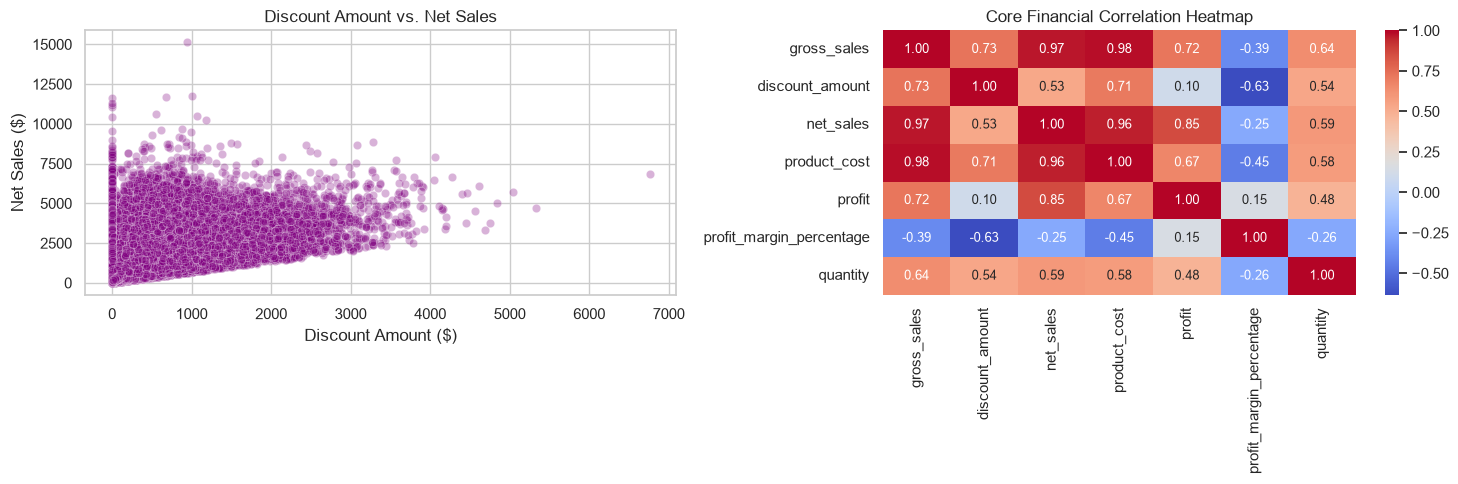

In [8]:
# 1. Visualizing Relationships & Core Correlations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Discount Amount vs Net Sales Scatter Plot
sns.scatterplot(data=df, x='discount_amount', y='net_sales', alpha=0.3, ax=axes[0], color='purple')
axes[0].set_title('Discount Amount vs. Net Sales')
axes[0].set_xlabel('Discount Amount ($)')
axes[0].set_ylabel('Net Sales ($)')

# Plot 2: Correlation Heatmap for Core Financial Features
core_financial_cols = ['gross_sales', 'discount_amount', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage', 'quantity']
sns.heatmap(df[core_financial_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], cbar=True, annot_kws={"size": 9})
axes[1].set_title('Core Financial Correlation Heatmap')

plt.tight_layout()
plt.show()

### Key Insights: Feature Relationships & Correlations
* **Discount Impact:** Higher discount amounts show a wide spread against net sales, indicating that steep discounts do not automatically guarantee higher net revenues[cite: 4].
* **Core Drivers:** Strong positive correlations exist between gross sales, net sales, and total profit, confirming that order value is the primary driver of profitability[cite: 4].

## Summary of Key Insights (Week 2 EDA)
* **Sales Channel Leadership:** Mobile App is the highest-volume sales channel, closely followed by direct Website purchases[cite: 4].
* **Regional Distribution:** Net sales and profit are evenly balanced across all geographic regions, showing strong margin consistency[cite: 4].
* **Seasonality & Profitability:** Sales follow a steady upward trend over time with predictable seasonal surges, while order value remains the primary driver of net profitability[cite: 4].